# Bluestock Mutual Fund Analytics

## Day 3: Exploratory Data Analysis (EDA)

### Objectives
- Analyze NAV trends across mutual fund schemes.
- Explore AUM and SIP inflow patterns.
- Understand investor demographics.
- Analyze geographic distribution.
- Study portfolio sector allocation.
- Identify correlations and business insights.

In [1]:
!pip install pandas numpy matplotlib seaborn plotly scipy jupyter

  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB 330.3 kB/s eta 0:00:30
   ---------------------------------------- 0.1/9.7 MB 595.3 kB/s eta 0:00:17
    --------------------------------------- 0.2/9.7 MB 766.6 kB/s eta 0:00:13
    --------------------------------------- 0.2/9.7 MB 901.1 kB/s eta 0:00:11
   - -------------------------------------- 0.5/9.7 MB 1.6 MB/s eta 0:00:06
   --- ------------------------------------ 0.9/9.7 MB 2.6 MB/s eta 0:00:04
   ---- ----------------------------------- 1.1/9.7 MB 2.8 MB/s eta 0:00:04
   ----- ---------------------------------- 1.2/9.7 MB 2.9 MB/s eta 0:00:03
   ------ ---------------------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


##### Import the libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("All libraries imported successfully!")

All libraries imported successfully!


##### Set up project paths

In [3]:
PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

REPORT_DIR = PROJECT_DIR / "reports"
CHART_DIR = REPORT_DIR / "eda_charts"

CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Chart directory:", CHART_DIR)

Project directory: D:\Bluestock Data Analyst Internship\Bluestock-Data-Analyst-Assignments\Bluestock-Mutual-Fund-Analytics
Raw data directory: D:\Bluestock Data Analyst Internship\Bluestock-Data-Analyst-Assignments\Bluestock-Mutual-Fund-Analytics\data\raw
Processed data directory: D:\Bluestock Data Analyst Internship\Bluestock-Data-Analyst-Assignments\Bluestock-Mutual-Fund-Analytics\data\processed
Chart directory: D:\Bluestock Data Analyst Internship\Bluestock-Data-Analyst-Assignments\Bluestock-Mutual-Fund-Analytics\reports\eda_charts


##### Load all 10 datasets

In [4]:
# Load all 10 datasets

fund_master = pd.read_csv(RAW_DIR / "01_fund_master.csv")

nav = pd.read_csv(PROCESSED_DIR / "clean_nav.csv")

aum = pd.read_csv(RAW_DIR / "03_aum_by_fund_house.csv")

sip = pd.read_csv(RAW_DIR / "04_monthly_sip_inflows.csv")

category_inflows = pd.read_csv(
    RAW_DIR / "05_category_inflows.csv"
)

folios = pd.read_csv(RAW_DIR / "06_industry_folio_count.csv")

performance = pd.read_csv(
    PROCESSED_DIR / "clean_performance.csv"
)

transactions = pd.read_csv(
    PROCESSED_DIR / "clean_transactions.csv"
)

portfolio = pd.read_csv(RAW_DIR / "09_portfolio_holdings.csv")

benchmarks = pd.read_csv(
    RAW_DIR / "10_benchmark_indices.csv"
)

print("All 10 datasets loaded successfully!")

All 10 datasets loaded successfully!


##### Create a dataset summary

In [5]:
datasets = {
    "Fund Master": fund_master,
    "NAV History": nav,
    "AUM": aum,
    "SIP Inflows": sip,
    "Category Inflows": category_inflows,
    "Folio Count": folios,
    "Performance": performance,
    "Transactions": transactions,
    "Portfolio Holdings": portfolio,
    "Benchmark Indices": benchmarks
}

summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum()
    }
    for name, df in datasets.items()
])

display(summary)

,Dataset,Rows,Columns,Missing Values
0,Fund Master,40,15,0
1,NAV History,46000,3,0
2,AUM,90,5,0
3,SIP Inflows,48,6,12
4,Category Inflows,144,3,0
5,Folio Count,21,6,0
6,Performance,40,21,0
7,Transactions,32778,13,0
8,Portfolio Holdings,322,8,0
9,Benchmark Indices,8050,3,0


##### Data preparation

In [6]:
# Convert date columns to datetime

nav["date"] = pd.to_datetime(nav["date"])
aum["date"] = pd.to_datetime(aum["date"])
sip["month"] = pd.to_datetime(sip["month"])
category_inflows["month"] = pd.to_datetime(category_inflows["month"])
folios["month"] = pd.to_datetime(folios["month"])
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)
portfolio["portfolio_date"] = pd.to_datetime(
    portfolio["portfolio_date"]
)
benchmarks["date"] = pd.to_datetime(benchmarks["date"])

# Sort datasets chronologically

nav = nav.sort_values(["amfi_code", "date"])
aum = aum.sort_values("date")
sip = sip.sort_values("month")
folios = folios.sort_values("month")

print("Date conversion completed successfully!")

Date conversion completed successfully!


##### Explore fund categories

category
Equity    34
Debt       6
Name: count, dtype: int64


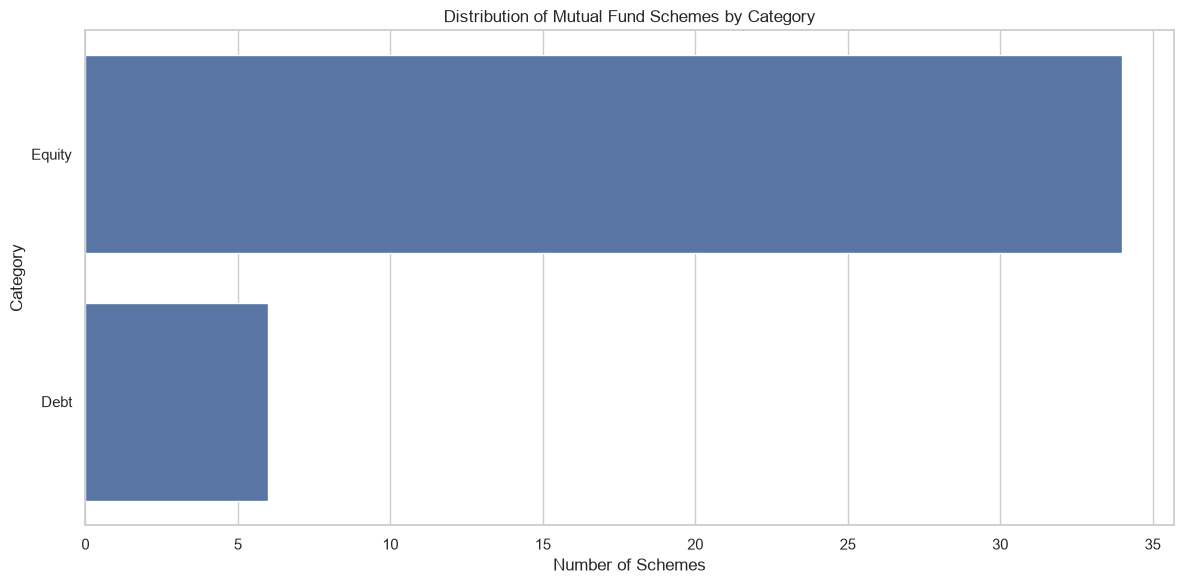

In [7]:
# Number of schemes by category

category_count = fund_master["category"].value_counts()

print(category_count)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_count.values,
    y=category_count.index
)

plt.title("Distribution of Mutual Fund Schemes by Category")
plt.xlabel("Number of Schemes")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(CHART_DIR / "01_fund_category_distribution.png")
plt.show()

##### NAV trend across all 40 schemes

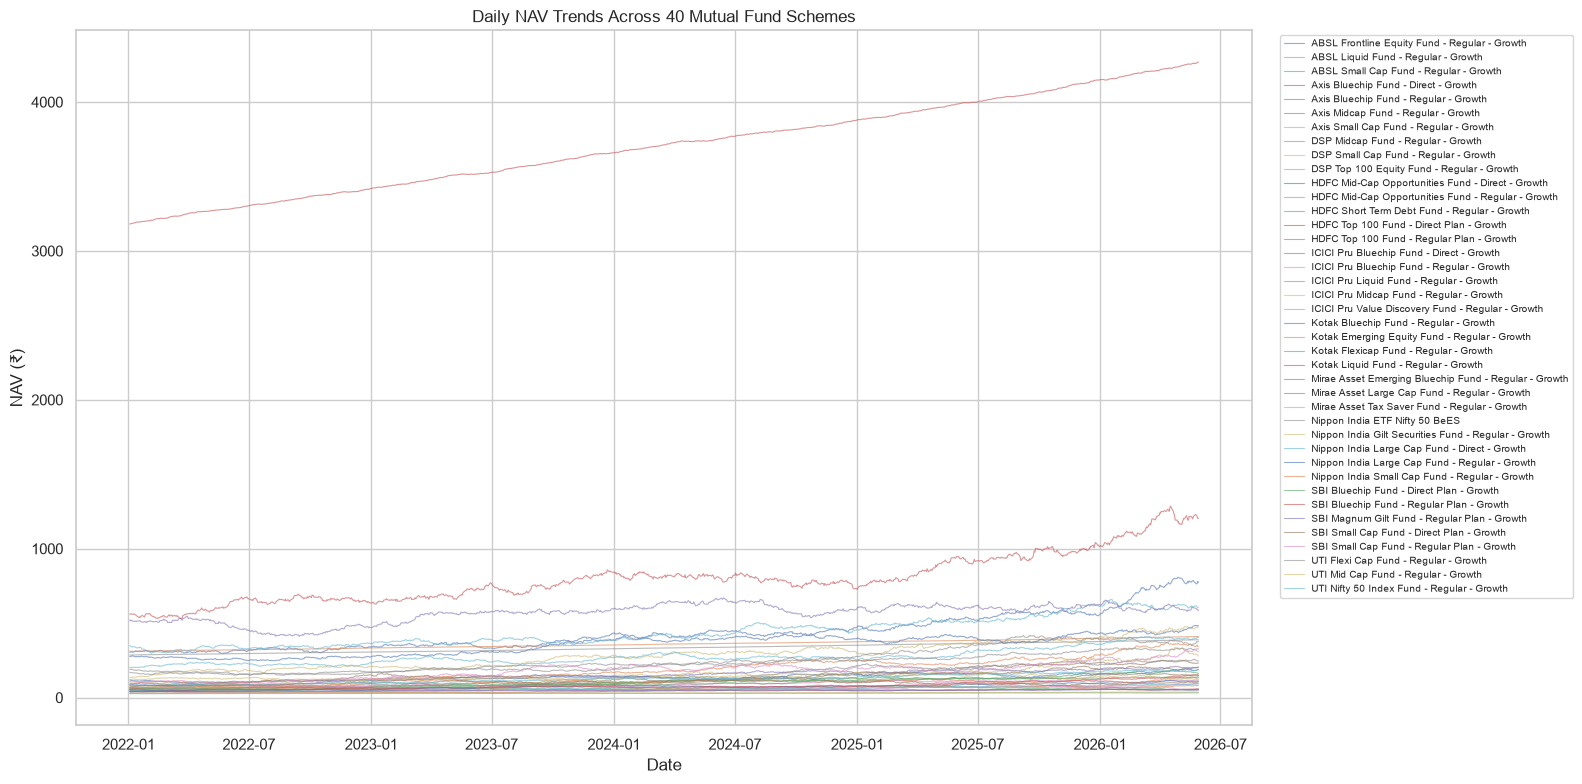

In [8]:
# Merge NAV with scheme names

nav_analysis = nav.merge(
    fund_master[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

plt.figure(figsize=(16, 8))

for scheme, group in nav_analysis.groupby("scheme_name"):
    plt.plot(
        group["date"],
        group["nav"],
        linewidth=0.8,
        alpha=0.6,
        label=scheme
    )

plt.title("Daily NAV Trends Across 40 Mutual Fund Schemes")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")
plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=7
)

plt.tight_layout()
plt.savefig(
    CHART_DIR / "02_nav_trends_all_schemes.png",
    bbox_inches="tight"
)
plt.show()

##### NAV trends of selected 5 schemes

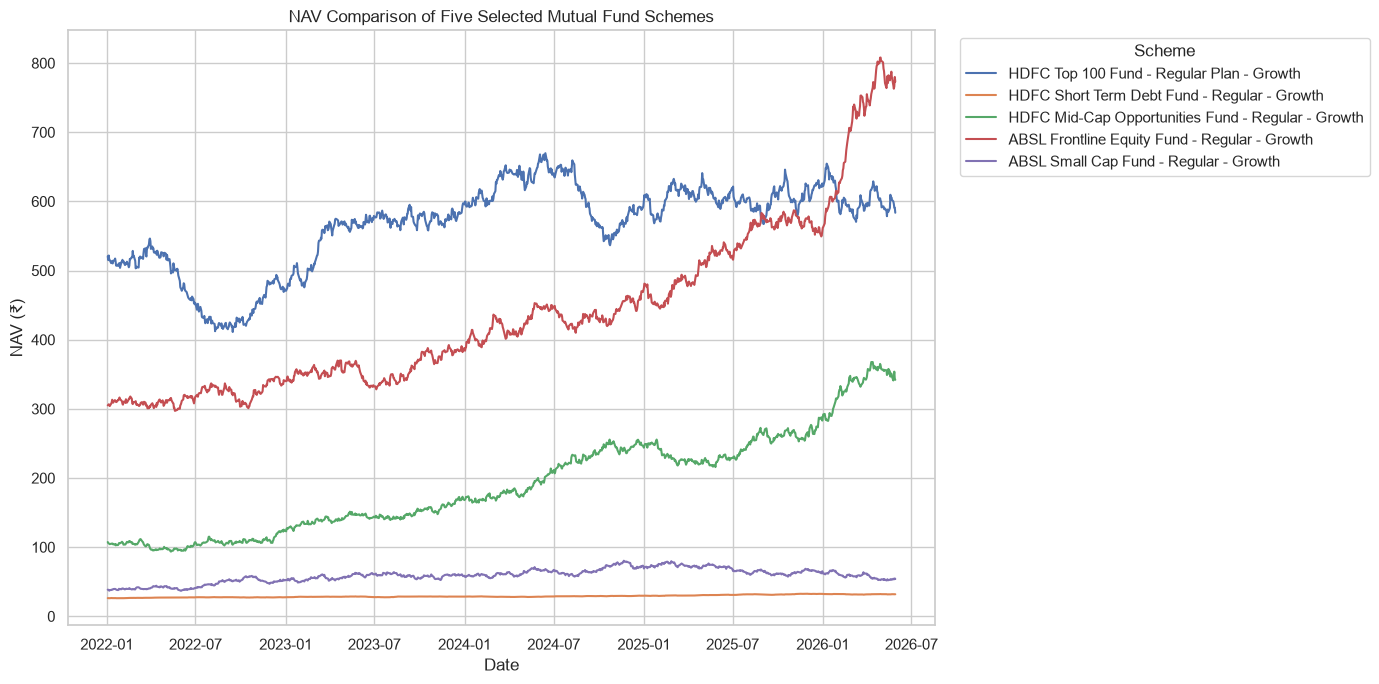

In [9]:
selected_codes = (
    nav["amfi_code"].value_counts().head(5).index
)

selected_nav = nav_analysis[
    nav_analysis["amfi_code"].isin(selected_codes)
]

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=selected_nav,
    x="date",
    y="nav",
    hue="scheme_name"
)

plt.title("NAV Comparison of Five Selected Mutual Fund Schemes")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")
plt.legend(title="Scheme", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.savefig(
    CHART_DIR / "03_selected_funds_nav_comparison.png",
    bbox_inches="tight"
)
plt.show()

##### AUM growth by fund house

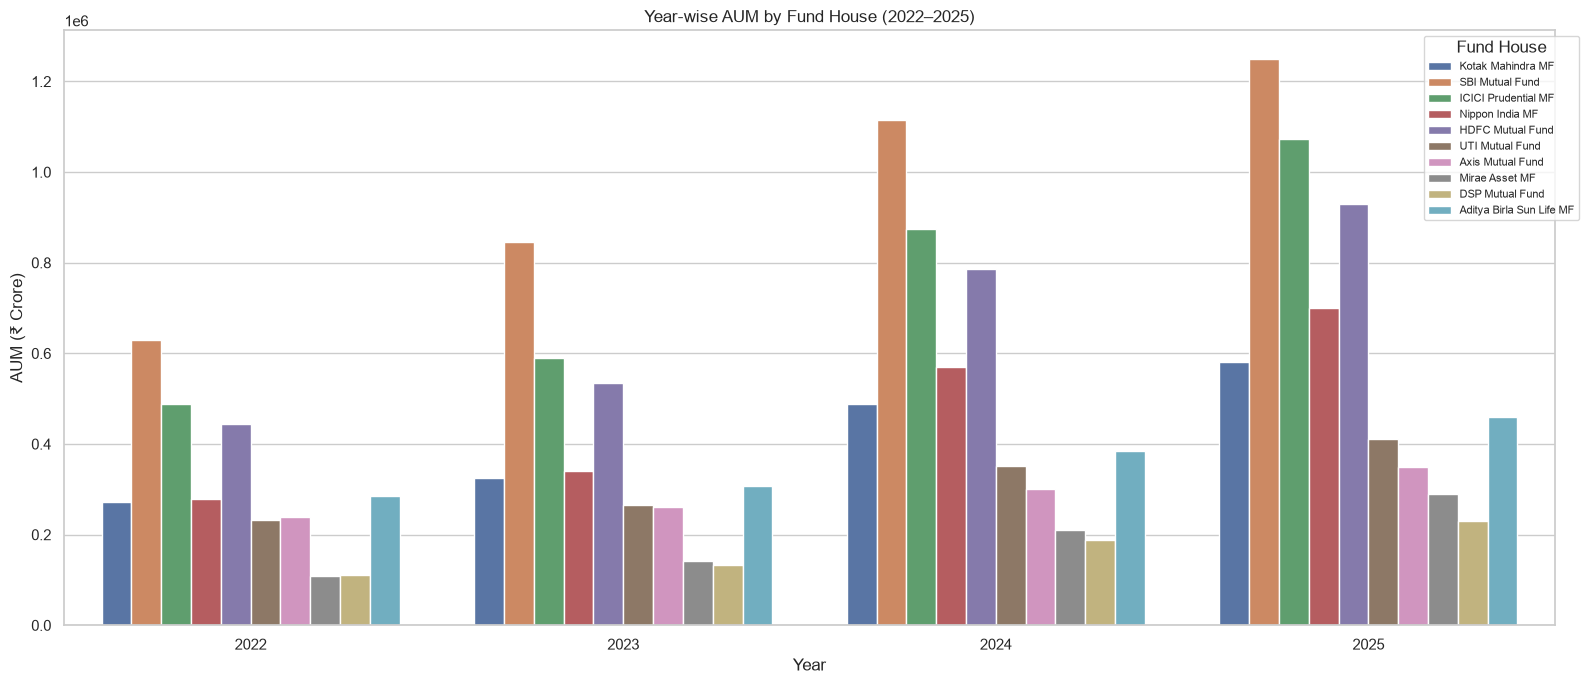

In [10]:
aum["year"] = aum["date"].dt.year

aum_yearly = (
    aum.sort_values("date")
    .groupby(["year", "fund_house"], as_index=False)
    .tail(1)
)

aum_yearly = aum_yearly[
    aum_yearly["year"].between(2022, 2025)
]

plt.figure(figsize=(16, 7))

sns.barplot(
    data=aum_yearly,
    x="year",
    y="aum_crore",
    hue="fund_house"
)

plt.title("Year-wise AUM by Fund House (2022–2025)")
plt.xlabel("Year")
plt.ylabel("AUM (₹ Crore)")
plt.legend(
    title="Fund House",
    bbox_to_anchor=(1.02, 1),
    fontsize=8
)

plt.tight_layout()
plt.savefig(
    CHART_DIR / "04_aum_growth_by_fund_house.png",
    bbox_inches="tight"
)
plt.show()

##### Monthly SIP inflow trend

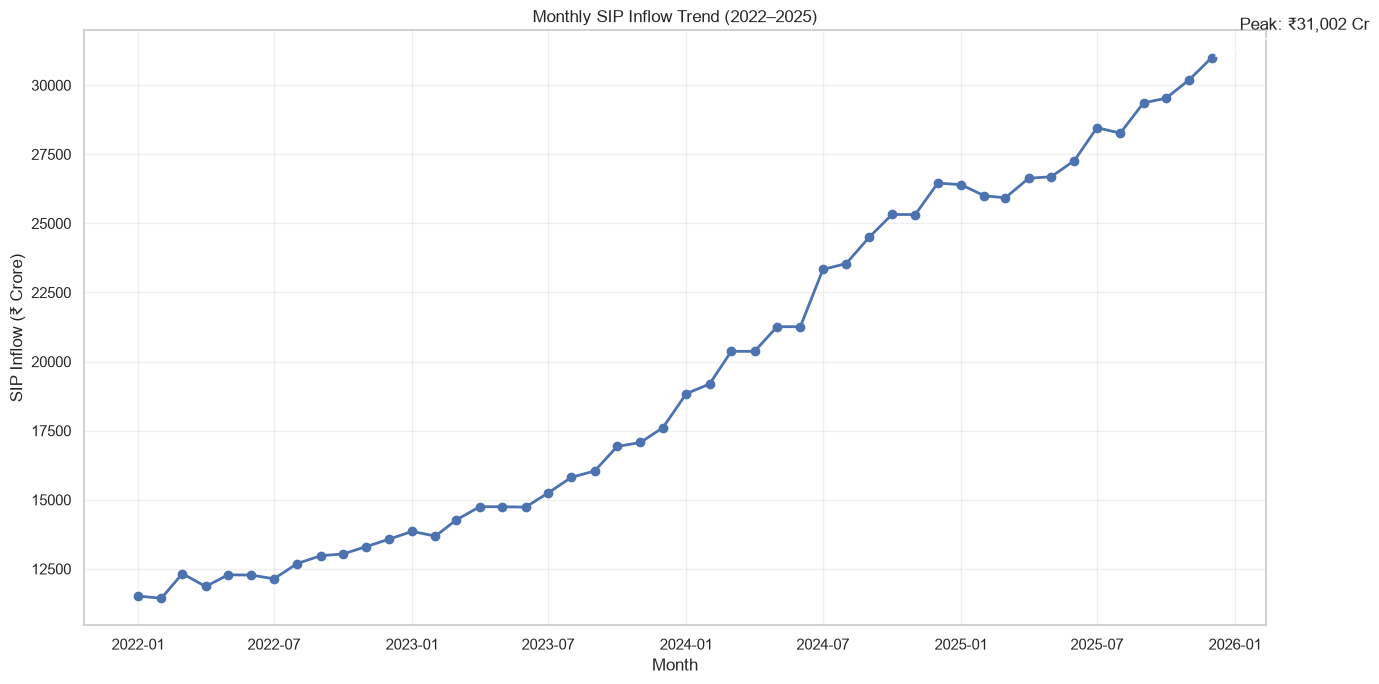

In [11]:
plt.figure(figsize=(14, 7))

plt.plot(
    sip["month"],
    sip["sip_inflow_crore"],
    marker="o",
    linewidth=2
)

plt.title("Monthly SIP Inflow Trend (2022–2025)")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ Crore)")
plt.grid(alpha=0.3)

# Highlight the maximum monthly SIP inflow in the dataset

max_sip = sip.loc[sip["sip_inflow_crore"].idxmax()]

plt.annotate(
    f"Peak: ₹{max_sip['sip_inflow_crore']:,.0f} Cr",
    xy=(max_sip["month"], max_sip["sip_inflow_crore"]),
    xytext=(20, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.savefig(CHART_DIR / "05_monthly_sip_inflow_trend.png")
plt.show()

##### Category-wise monthly inflow heatmap

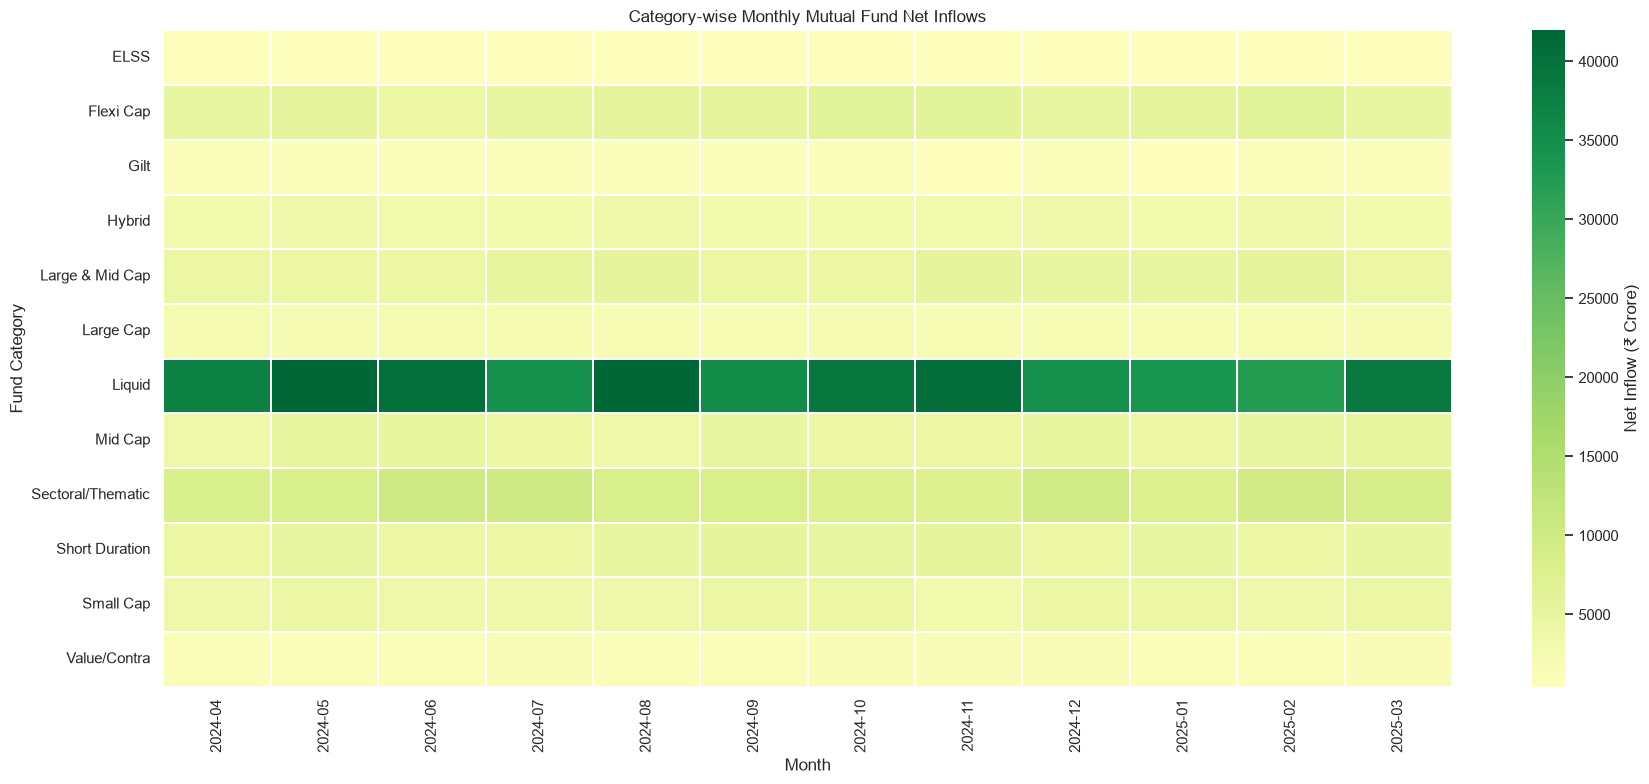

In [12]:
# Prepare category-wise monthly inflow data

category_pivot = category_inflows.pivot_table(
    index="category",
    columns=category_inflows["month"].dt.strftime("%Y-%m"),
    values="net_inflow_crore",
    aggfunc="sum"
)

plt.figure(figsize=(18, 8))

sns.heatmap(
    category_pivot,
    cmap="RdYlGn",
    center=0,
    linewidths=0.3,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Category-wise Monthly Mutual Fund Net Inflows")
plt.xlabel("Month")
plt.ylabel("Fund Category")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "06_category_inflow_heatmap.png",
    bbox_inches="tight"
)
plt.show()

##### Investor age group distribution

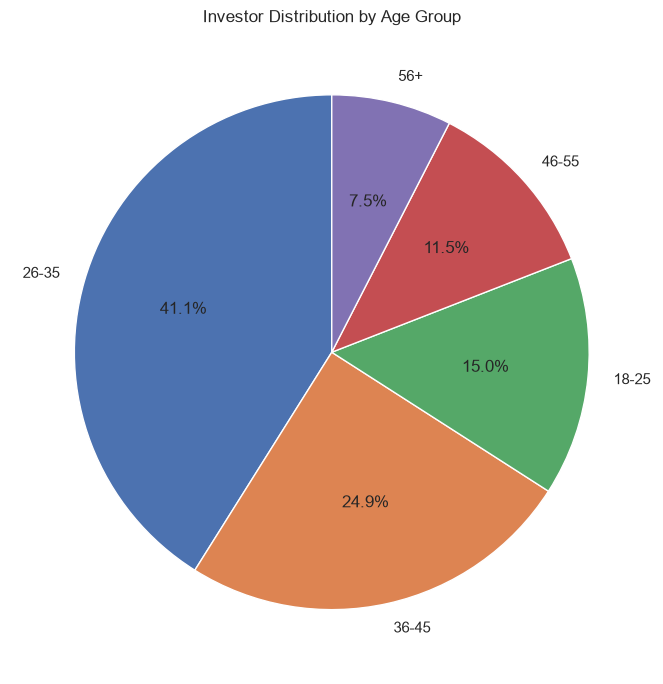

In [13]:
age_distribution = transactions["age_group"].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    age_distribution.values,
    labels=age_distribution.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Distribution by Age Group")
plt.tight_layout()

plt.savefig(CHART_DIR / "07_investor_age_distribution.png")
plt.show()

##### SIP transaction amount by age group

Total SIP transactions: 19716


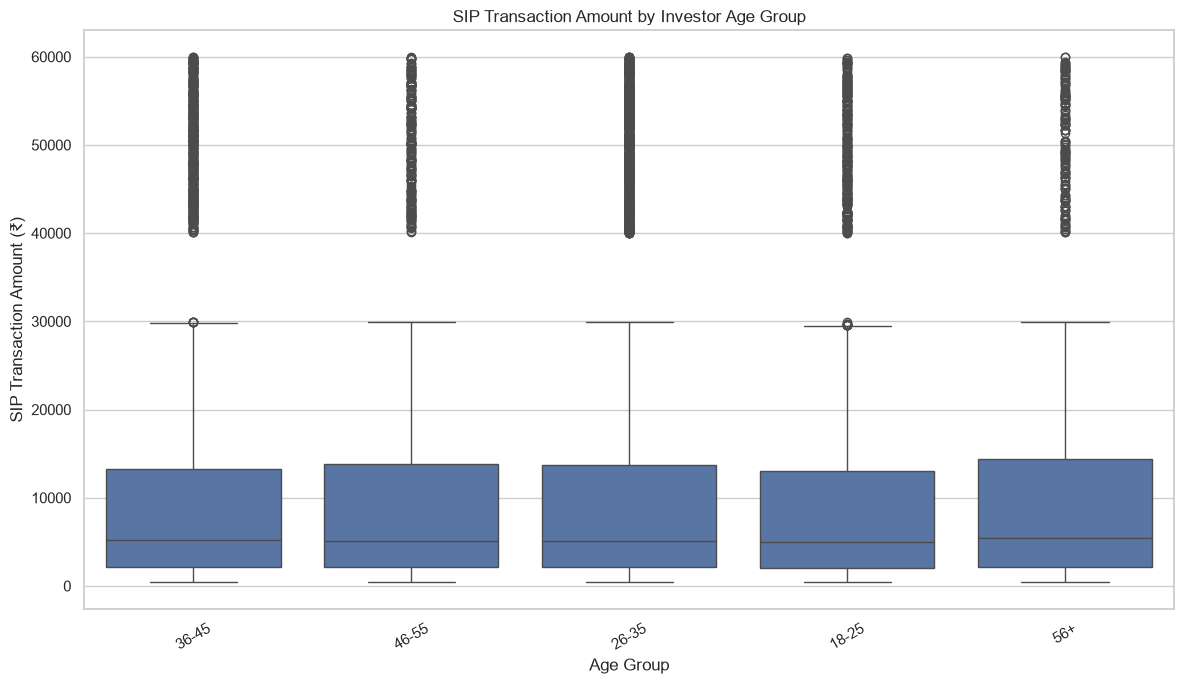

In [14]:
sip_transactions = transactions[
    transactions["transaction_type"]
    .astype(str).str.strip().str.upper() == "SIP"
].copy()

print("Total SIP transactions:", len(sip_transactions))

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=sip_transactions,
    x="age_group",
    y="amount_inr"
)

plt.title("SIP Transaction Amount by Investor Age Group")
plt.xlabel("Age Group")
plt.ylabel("SIP Transaction Amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "08_sip_amount_by_age_group.png",
    bbox_inches="tight"
)
plt.show()

##### State-wise SIP investment distribution

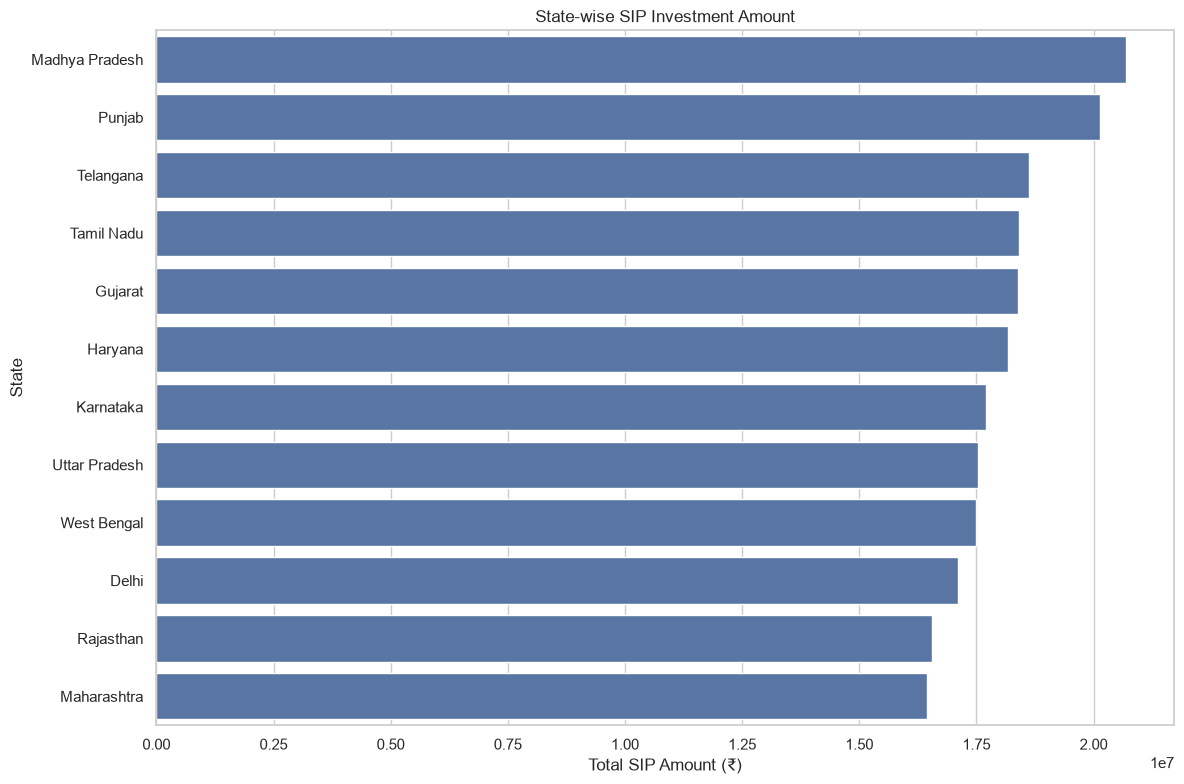

In [15]:
state_sip = (
    sip_transactions.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=state_sip.values,
    y=state_sip.index
)

plt.title("State-wise SIP Investment Amount")
plt.xlabel("Total SIP Amount (₹)")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "09_state_wise_sip_investment.png",
    bbox_inches="tight"
)
plt.show()

##### T30 vs B30 investor distribution

city_tier
T30    21719
B30    11059
Name: count, dtype: int64


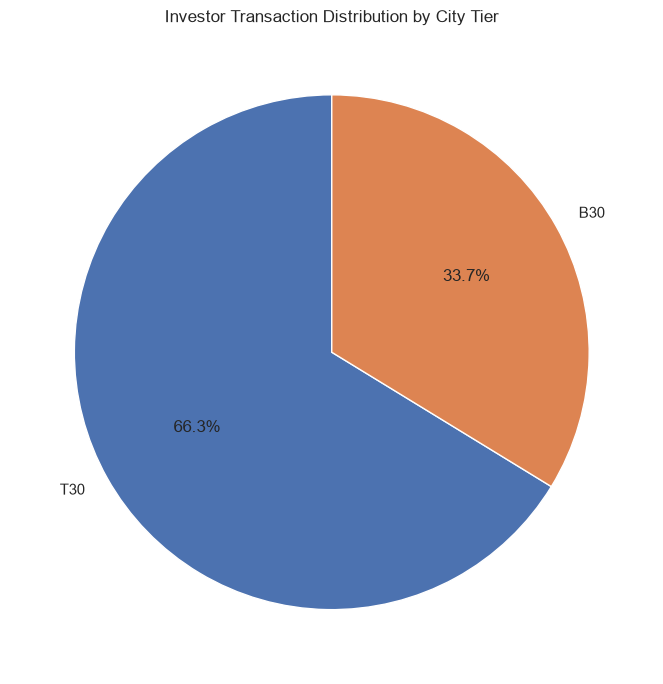

In [16]:
city_distribution = (
    transactions["city_tier"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.upper()
    .value_counts()
)

print(city_distribution)

plt.figure(figsize=(9, 7))

plt.pie(
    city_distribution.values,
    labels=city_distribution.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Investor Transaction Distribution by City Tier")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "10_city_tier_distribution.png"
)
plt.show()

##### Industry folio count growth

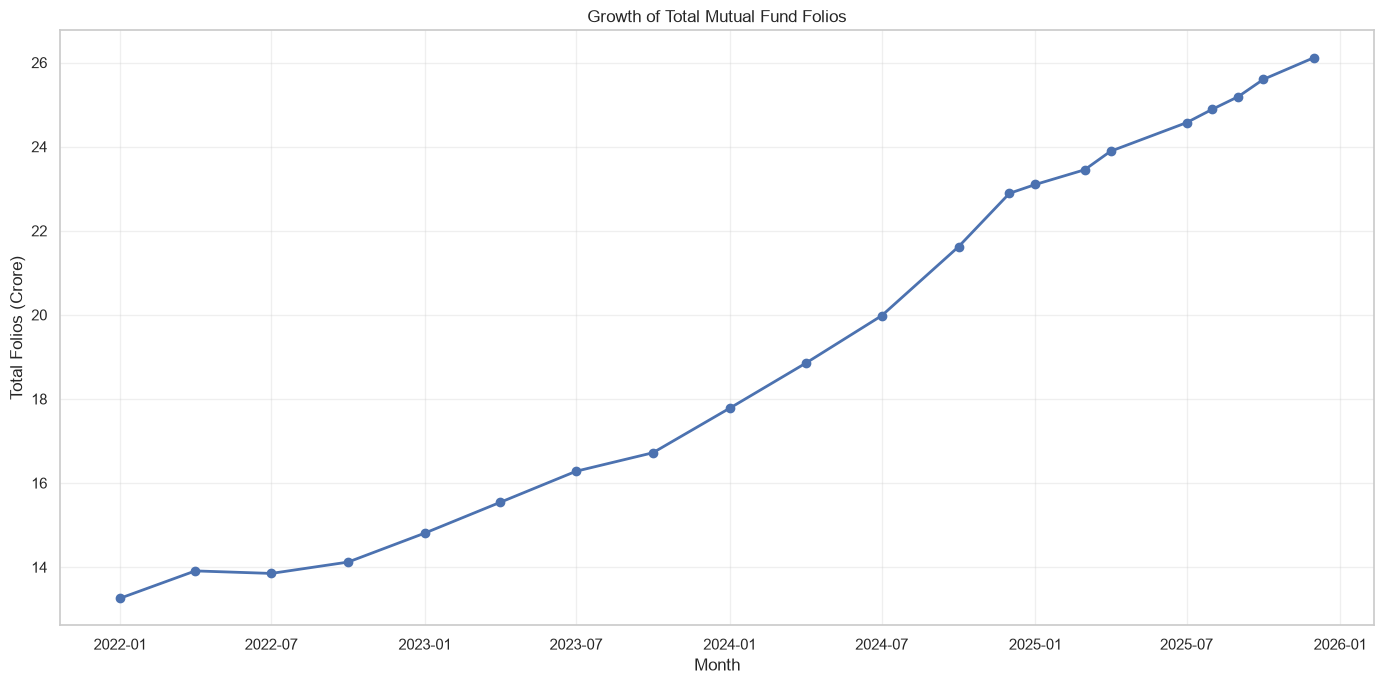

In [17]:
folios = folios.sort_values("month")

plt.figure(figsize=(14, 7))

plt.plot(
    folios["month"],
    folios["total_folios_crore"],
    marker="o",
    linewidth=2
)

plt.title("Growth of Total Mutual Fund Folios")
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "11_folio_count_growth.png"
)
plt.show()

##### NAV return correlation matrix

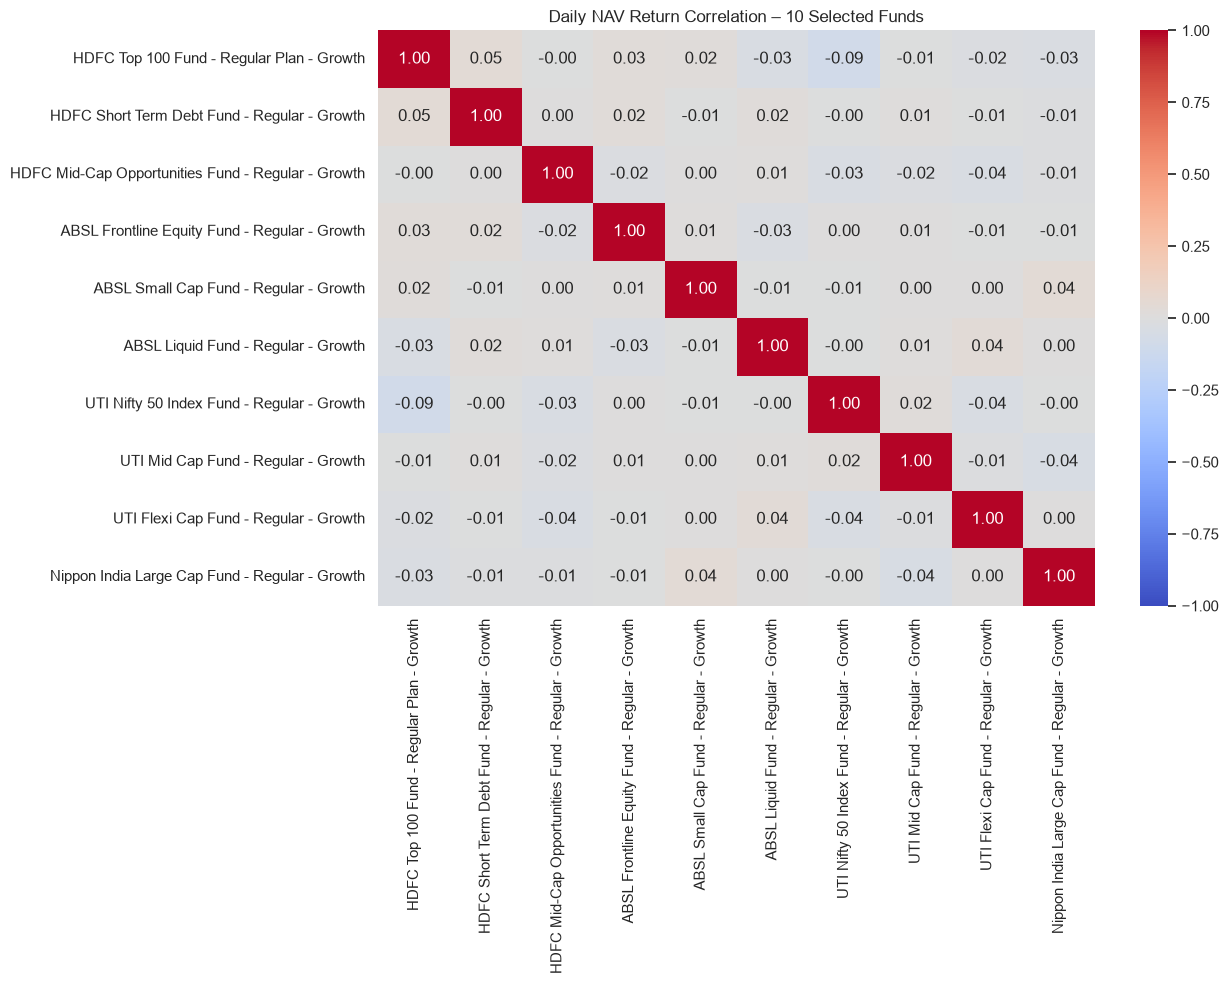

In [18]:
# Select 10 schemes with the most NAV observations

selected_codes = (
    nav.groupby("amfi_code")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .index
)

selected_nav = nav[
    nav["amfi_code"].isin(selected_codes)
].copy()

# Convert NAV data into a date-by-scheme matrix

nav_pivot = selected_nav.pivot_table(
    index="date",
    columns="amfi_code",
    values="nav"
).sort_index()

# Calculate daily percentage returns

nav_returns = nav_pivot.pct_change(fill_method=None)

# Calculate pairwise correlations

correlation_matrix = nav_returns.corr(
    min_periods=30
)

# Add scheme names for readability

scheme_names = fund_master.set_index(
    "amfi_code"
)["scheme_name"]

correlation_matrix.columns = [
    scheme_names.get(code, str(code))
    for code in correlation_matrix.columns
]

correlation_matrix.index = correlation_matrix.columns

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Daily NAV Return Correlation – 10 Selected Funds")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "12_nav_return_correlation.png",
    bbox_inches="tight"
)
plt.show()

##### Portfolio sector allocation

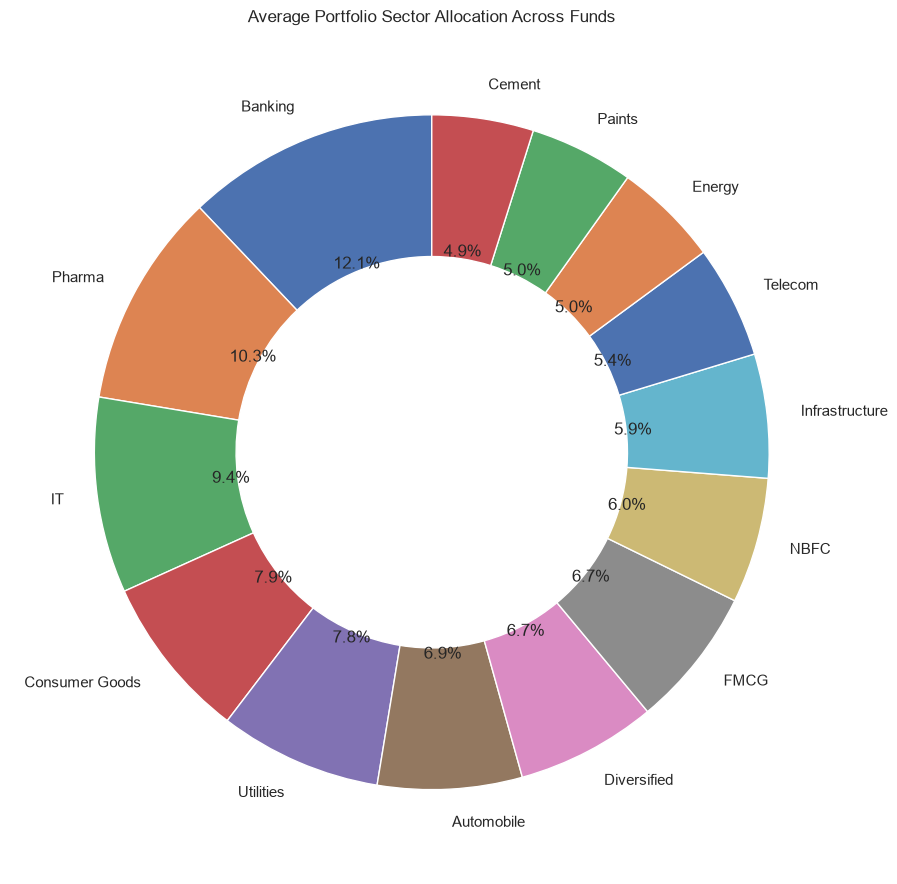

In [19]:
# Calculate sector allocation within each fund

fund_sector_weights = (
    portfolio.groupby(
        ["amfi_code", "sector"]
    )["weight_pct"]
    .sum()
    .reset_index()
)

# Calculate average sector allocation across funds

sector_allocation = (
    fund_sector_weights.groupby("sector")["weight_pct"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 9))

plt.pie(
    sector_allocation.values,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)

plt.title("Average Portfolio Sector Allocation Across Funds")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "13_portfolio_sector_allocation.png",
    bbox_inches="tight"
)
plt.show()

##### Transaction type distribution

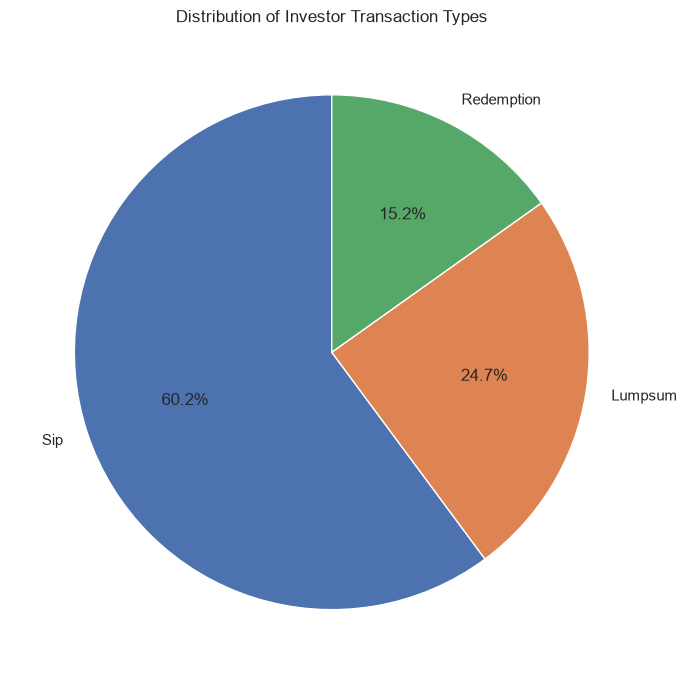

In [20]:
transaction_distribution = (
    transactions["transaction_type"]
    .value_counts()
)

plt.figure(figsize=(9, 7))

plt.pie(
    transaction_distribution.values,
    labels=transaction_distribution.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Investor Transaction Types")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "14_transaction_type_distribution.png"
)
plt.show()

##### Fund return vs risk comparison

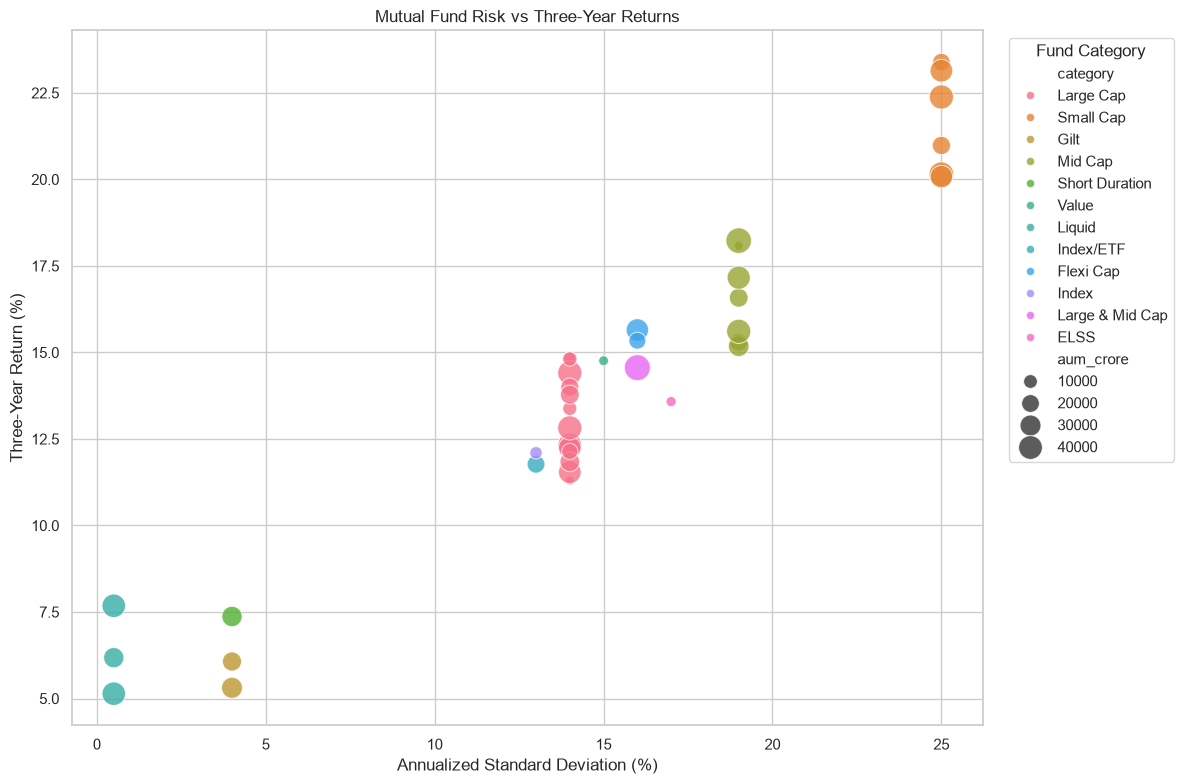

In [21]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=performance,
    x="std_dev_ann_pct",
    y="return_3yr_pct",
    hue="category",
    size="aum_crore",
    sizes=(40, 350),
    alpha=0.8
)

plt.title("Mutual Fund Risk vs Three-Year Returns")
plt.xlabel("Annualized Standard Deviation (%)")
plt.ylabel("Three-Year Return (%)")
plt.legend(
    title="Fund Category",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "15_fund_risk_return_comparison.png",
    bbox_inches="tight"
)
plt.show()

##### EDA findings and validation

In [22]:
# 1. Most common fund category
top_category = fund_master["category"].value_counts().idxmax()
top_category_count = fund_master["category"].value_counts().max()

# 2. Fund house with highest latest AUM
latest_aum = (
    aum.sort_values("date")
    .groupby("fund_house")
    .tail(1)
)

top_amc = latest_aum.loc[
    latest_aum["aum_crore"].idxmax()
]

# 3. Month with highest SIP inflow
peak_sip = sip.loc[sip["sip_inflow_crore"].idxmax()]

# 4. Most common investor age group
top_age = transactions["age_group"].value_counts().idxmax()

# 5. State with highest SIP amount
top_state = state_sip.idxmax()

# 6. Folio growth
first_folio = folios.iloc[0]["total_folios_crore"]
last_folio = folios.iloc[-1]["total_folios_crore"]

# 7. Highest average portfolio sector allocation
top_sector = sector_allocation.idxmax()
top_sector_weight = sector_allocation.max()

# 8. Highest three-year return
best_return = performance.loc[
    performance["return_3yr_pct"].idxmax()
]

# 9. Highest Sharpe ratio
best_sharpe = performance.loc[
    performance["sharpe_ratio"].idxmax()
]

# 10. Strongest positive NAV return correlation
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

correlations = upper_triangle.stack().dropna()

if not correlations.empty:
    strongest_pair = correlations.idxmax()
    strongest_value = correlations.max()
else:
    strongest_pair = ("Not available", "Not available")
    strongest_value = np.nan

findings = [
    f"1. {top_category} has the highest number of schemes in the fund master dataset ({top_category_count}).",

    f"2. {top_amc['fund_house']} has the highest latest recorded AUM (₹{top_amc['aum_crore']:,.2f} crore).",

    f"3. The highest SIP inflow was recorded in {peak_sip['month']} (₹{peak_sip['sip_inflow_crore']:,.2f} crore).",

    f"4. The most frequently represented investor age group is {top_age}.",

    f"5. {top_state} has the highest total SIP transaction amount.",

    f"6. Total folios changed from {first_folio:.2f} crore to {last_folio:.2f} crore over the available observation period.",

    f"7. {top_sector} has the highest average portfolio sector allocation ({top_sector_weight:.2f}%).",

    f"8. {best_return['scheme_name']} has the highest three-year return ({best_return['return_3yr_pct']:.2f}%).",

    f"9. {best_sharpe['scheme_name']} has the highest Sharpe ratio ({best_sharpe['sharpe_ratio']:.2f}).",

    f"10. The strongest positive NAV return correlation is between {strongest_pair[0]} and {strongest_pair[1]} ({strongest_value:.3f})."
]

for finding in findings:
    print(finding)
    print()

1. Equity has the highest number of schemes in the fund master dataset (34).

2. SBI Mutual Fund has the highest latest recorded AUM (₹1,250,000.00 crore).

3. The highest SIP inflow was recorded in 2025-12-01 00:00:00 (₹31,002.00 crore).

4. The most frequently represented investor age group is 26-35.

5. Madhya Pradesh has the highest total SIP transaction amount.

6. Total folios changed from 13.26 crore to 26.12 crore over the available observation period.

7. Banking has the highest average portfolio sector allocation (21.74%).

8. SBI Small Cap Fund - Regular Plan - Growth has the highest three-year return (23.39%).

9. ICICI Pru Liquid Fund - Regular - Growth has the highest Sharpe ratio (7.68).

10. The strongest positive NAV return correlation is between HDFC Top 100 Fund - Regular Plan - Growth and HDFC Short Term Debt Fund - Regular - Growth (0.046).



##### Save EDA findings

In [23]:
findings_path = REPORT_DIR / "EDA_Findings.txt"

with open(findings_path, "w", encoding="utf-8") as file:
    file.write("BLUESTOCK MUTUAL FUND ANALYTICS\n")
    file.write("DAY 3: EXPLORATORY DATA ANALYSIS FINDINGS\n")
    file.write("=" * 60 + "\n\n")

    for finding in findings:
        file.write(finding + "\n\n")

print("EDA findings saved successfully!")
print("File location:", findings_path)

EDA findings saved successfully!
File location: D:\Bluestock Data Analyst Internship\Bluestock-Data-Analyst-Assignments\Bluestock-Mutual-Fund-Analytics\reports\EDA_Findings.txt


##### Verify all exported charts

In [24]:
chart_files = list(CHART_DIR.glob("*.png"))

print("Total charts generated:", len(chart_files))
print("\nChart inventory:")

for chart in sorted(chart_files):
    print(chart.name)

if len(chart_files) >= 15:
    print("\nEDA chart requirement achieved!")
else:
    print("\nMore charts are required.")

Total charts generated: 15

Chart inventory:
01_fund_category_distribution.png
02_nav_trends_all_schemes.png
03_selected_funds_nav_comparison.png
04_aum_growth_by_fund_house.png
05_monthly_sip_inflow_trend.png
06_category_inflow_heatmap.png
07_investor_age_distribution.png
08_sip_amount_by_age_group.png
09_state_wise_sip_investment.png
10_city_tier_distribution.png
11_folio_count_growth.png
12_nav_return_correlation.png
13_portfolio_sector_allocation.png
14_transaction_type_distribution.png
15_fund_risk_return_comparison.png

EDA chart requirement achieved!


##### Final EDA dataset summary

In [25]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total mutual fund schemes",
        "Total NAV observations",
        "Total fund houses",
        "Total SIP observations",
        "Total investor transactions",
        "Total portfolio holdings",
        "Total benchmark observations",
        "Total visualizations"
    ],
    "Value": [
        fund_master["amfi_code"].nunique(),
        len(nav),
        aum["fund_house"].nunique(),
        len(sip),
        len(transactions),
        len(portfolio),
        len(benchmarks),
        len(chart_files)
    ]
})

display(eda_summary)

,Metric,Value
0,Total mutual fund schemes,40
1,Total NAV observations,46000
2,Total fund houses,10
3,Total SIP observations,48
4,Total investor transactions,32778
5,Total portfolio holdings,322
6,Total benchmark observations,8050
7,Total visualizations,15


In [26]:
print("Total charts generated:", len(chart_files))

Total charts generated: 15
